# PaleographIA · Notebook 3 — PLN depois do reconhecimento

**Projeto Integrador IV e Processamento de Linguagem Natural** · grupo 7: Caio Augusto de Souza Soares,
Guilherme Rodrigues Veiga, Rodolfo Vinicius Cima Takemoto e Tiago Galhardo Avelar.

**Problema.** Ler manuscritos históricos em português dos séculos XVII a XIX do Arquivo Histórico de
Jundiaí exige tempo e paleógrafos. O PaleographIA sugere uma leitura de cada linha; um humano confere
e valida. Reconhecimento bruto, sugestão e transcrição humana ficam sempre separados.

**Este notebook** reúne as duas comparações pedidas e a parte de texto do projeto:

1. **Comparação 1 — modelos:** PP-OCRv6 base × ajustado A (Traslado) × ajustado B (Traslado + Inquisição).
2. **Análise linguística dos erros:** que tipos de erro sobram e quanto do CER cada um explica.
3. **Comparação 2 — pós-correção lexical:** método A (Levenshtein) × método B (TF-IDF de n-gramas de caracteres).

Tudo roda em CPU, sem GPU nem Docker: usa as predições já salvas no repositório. As métricas são
CER e WER (taxa de erro de caracteres e de palavras; menor é melhor), em NFC, preservando maiúsculas,
acentos, pontuação e grafia. **Os números são de desenvolvimento**: a validação tem 7 linhas da sessão
de 1795 (345 caracteres), e o teste reservado ainda não foi usado.

In [1]:
# Localiza o repositório (local) ou baixa o código público (Colab). Só Python puro + jiwer + matplotlib.
import os, subprocess, sys
from pathlib import Path

raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/paleographia/pln_erros.py").exists()), None)
if raiz is None:  # Colab ou pasta solta
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/aj1no/paleographia-htr.git"], check=True)
    raiz = Path("paleographia-htr").resolve()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "jiwer"], check=True)
sys.path.insert(0, str(raiz / "src")); sys.path.insert(0, str(raiz / "scripts"))
os.chdir(raiz)
import analise_pln
from paleographia.pln_erros import TIPOS, COSSENO_MINIMO, TAMANHO_MINIMO, NGRAMAS
r = analise_pln.main()
print("Repositório:", raiz.name, "| modelos avaliados:", ", ".join(r["modelos"]))

Repositório: PaleographIA | modelos avaliados: PP-OCRv6 base, Ajustado A (Traslado), Ajustado B (Traslado + Inquisição)


## 1. Comparação 1 — PP-OCRv6 base × ajustado

Os três modelos leem os **mesmos recortes** das 7 linhas de validação pelo worker de inferência do
editor. O ajuste fino (adaptação de domínio, como LEGAL-BERT ou BioMistral na aula 09) partiu do
PP-OCRv6 medium, um modelo de sequência para sequência que gera a linha caractere a caractere
(vocabulário por caractere, aulas 02 e 05). A treinou só com o Traslado de Jundiaí (191 linhas); B
somou 550 linhas públicas de processos da Inquisição (CC BY 4.0). Treinos gravados em 06/11 e 07/11.

Modelo                                      CER      WER
PP-OCRv6 base                            14.20%   56.72%
Ajustado A (Traslado)                    10.72%   41.79%
Ajustado B (Traslado + Inquisição)       10.14%   38.81%


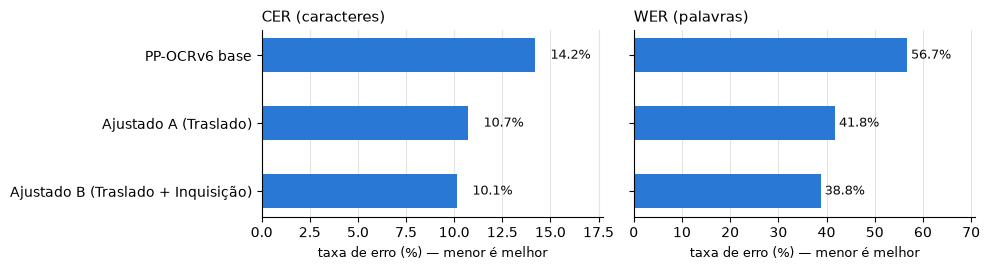

In [2]:
import matplotlib.pyplot as plt

nomes = list(r["modelos"])
print(f"{'Modelo':38s} {'CER':>8s} {'WER':>8s}")
for n in nomes:
    b = r["modelos"][n]["bruto"]
    print(f"{n:38s} {b['cer']:8.2%} {b['wer']:8.2%}")

fig, eixos = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
for eixo, chave, titulo in zip(eixos, ["cer", "wer"], ["CER (caracteres)", "WER (palavras)"]):
    valores = [r["modelos"][n]["bruto"][chave] * 100 for n in nomes]
    eixo.barh(nomes, valores, color="#2a78d6", height=0.5)
    for y, v in enumerate(valores):
        eixo.text(v + 0.8, y, f"{v:.1f}%", va="center", fontsize=9, color="#0b0b0b")
    eixo.set_title(titulo, loc="left", fontsize=11)
    eixo.set_xlim(0, max(valores) * 1.25)
    eixo.spines[["top", "right"]].set_visible(False); eixo.grid(axis="x", color="#e4e3df"); eixo.set_axisbelow(True)
    eixo.set_xlabel("taxa de erro (%) — menor é melhor", fontsize=9)
eixos[0].invert_yaxis()  # eixo y compartilhado: inverter uma vez só
plt.tight_layout(); plt.show()

In [3]:
# Leitura linha a linha: referência humana, base e ajustado B.
linhas = {n: r["modelos"][n]["pos_correcao"]["A"]["linhas"] for n in nomes}
for i, l in enumerate(linhas[nomes[0]]):
    print(f"{i+1}. REF   {l['referencia']}")
    print(f"   base  {l['bruto']}")
    print(f"   B     {linhas[nomes[-1]][i]['bruto']}\n")

1. REF   Aos vinte e cinco dias do mes de junho de mil sete
   base  Aos vinte ecenco dia domes de Iunho demil sette
   B     Aos vinte ecenco dias do mes de Iunho de mil sette

2. REF   centos e noventa e cinco annos nesta Villa de Nˢᵃ
   base  centos e noventa ainco annos nesta villa da Nossa
   B     centos e noventa ainco annos nesta villa da Nossa

3. REF   senhora do Desterro de jundiahy comarca da cidade
   base  senhora do Desterro de Iundiahi Comarca da Cidade
   B     senhora do Desterro de Iundiahi Comarca da Cidade

4. REF   de São Paulo, em casas de morada do Juiz Presidente
   base  de Saõ Paulo em Cazas de morada do Iuis Prezidente
   B     de Saõ Paulo em Cazas de morada do Iuis Prezidente

5. REF   Salvador de Oliveira Prado, onde se achavão presentes
   base  Selvador de Oliviera Prado, onde se achavaõ prezenty
   B     Selvador de Oliveira Prado, onde se achavaõ prezentes

6. REF   os officiaes da Camara em acto de Vereança, trat-
   base  os Officiays de Camara em a

**Leitura.** O ajuste fino reduziu o CER de 14,2% para cerca de 10–11% e o WER de 57% para 39–42%.
A diferença entre A e B (cerca de 2 caracteres em 345) está dentro da variação entre execuções: dois
treinos de A com a mesma configuração deram 12,2% e 10,7%. Com 7 linhas, só dá para afirmar que o
ajuste melhora; o tamanho exato da melhora fica para o teste reservado.

## 2. Análise linguística dos erros

Cada linha prevista é alinhada à referência por distância de edição (Levenshtein, com rastreio). Cada
substituição, apagamento ou inserção recebe um tipo, nesta ordem de prioridade:

| Tipo | Regra |
|---|---|
| espaço | envolve um espaço: palavras coladas ("dopovo") ou separadas |
| pontuação | envolve sinal de pontuação |
| abreviatura | a palavra da referência tem letra sobrescrita ou ponto ("Nˢᵃ") |
| maiúscula/minúscula | mesma letra, caixa diferente ("casas" → "Cazas", no "c") |
| acento ou til | mesma letra sem o diacrítico ("São" → "Saõ") |
| grafia histórica | alternâncias da época: i/j, u/v, i/y, s/z, c/s, ç/s, s/x, e/i, o/u |
| nome próprio | dentro de palavra com maiúscula fora do início da linha |
| forma da letra | o resto: a letra foi lida como outra |

A soma dos tipos é exatamente o número de erros do CER.

Tipo                                       PP-OCRv6 base      Ajustado A      Ajustado B
espaço (palavras coladas ou separadas)          7 ( 14%)        4 ( 11%)        3 (  9%)
pontuação                                       2 (  4%)        2 (  5%)        2 (  6%)
abreviatura                                     4 (  8%)        4 ( 11%)        4 ( 11%)
maiúscula/minúscula                             5 ( 10%)        8 ( 22%)        5 ( 14%)
acento ou til                                   5 ( 10%)        1 (  3%)        4 ( 11%)
grafia histórica                               11 ( 22%)        5 ( 14%)        9 ( 26%)
nome próprio                                    1 (  2%)        1 (  3%)        1 (  3%)
forma da letra                                 14 ( 29%)       12 ( 32%)        7 ( 20%)
total de erros                                        49              37              35


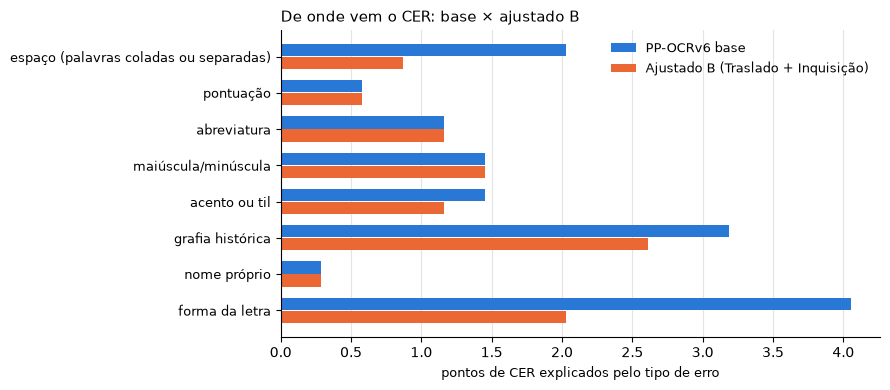

In [4]:
print(f"{'Tipo':40s}" + "".join(f"{n.split(' (')[0]:>16s}" for n in nomes))
for t in TIPOS:
    print(f"{t:40s}" + "".join(f"{r['modelos'][n]['erros']['por_tipo'][t]['erros']:>9d} ({r['modelos'][n]['erros']['por_tipo'][t]['parcela_dos_erros']:4.0%})" for n in nomes))
print(f"{'total de erros':40s}" + "".join(f"{r['modelos'][n]['erros']['erros']:>16d}" for n in nomes))

base, melhor = nomes[0], nomes[-1]
y = range(len(TIPOS))
fig, eixo = plt.subplots(figsize=(9, 4))
pb = [r["modelos"][base]["erros"]["por_tipo"][t]["pontos_de_cer"] * 100 for t in TIPOS]
pm = [r["modelos"][melhor]["erros"]["por_tipo"][t]["pontos_de_cer"] * 100 for t in TIPOS]
eixo.barh([i - 0.18 for i in y], pb, height=0.34, color="#2a78d6", label="PP-OCRv6 base")
eixo.barh([i + 0.18 for i in y], pm, height=0.34, color="#eb6834", label=melhor)
eixo.set_yticks(list(y), TIPOS, fontsize=9); eixo.invert_yaxis()
eixo.set_xlabel("pontos de CER explicados pelo tipo de erro", fontsize=9)
eixo.set_title("De onde vem o CER: base × ajustado B", loc="left", fontsize=11)
eixo.spines[["top", "right"]].set_visible(False); eixo.grid(axis="x", color="#e4e3df"); eixo.set_axisbelow(True)
eixo.legend(frameon=False, fontsize=9, loc="upper right"); plt.tight_layout(); plt.show()

In [5]:
# Confusões de caracteres mais frequentes (∅ = caractere ausente).
for n in (base, melhor):
    print(n)
    for c in r["modelos"][n]["erros"]["confusoes"][:10]:
        print(f"   referência {c['referencia']!r:6s} → predição {c['predicao']!r:6s}  {c['vezes']}×")

PP-OCRv6 base
   referência ' '    → predição '∅'     7×
   referência 'e'    → predição '∅'     3×
   referência 'c'    → predição 'C'     3×
   referência 's'    → predição 'z'     3×
   referência 'i'    → predição 'e'     2×
   referência 'j'    → predição 'I'     2×
   referência 'ã'    → predição 'a'     2×
   referência 'o'    → predição 'õ'     2×
   referência 'a'    → predição 'e'     2×
   referência 's'    → predição 'y'     2×
Ajustado B (Traslado + Inquisição)
   referência ' '    → predição '∅'     3×
   referência 'c'    → predição 'C'     3×
   referência 's'    → predição 'z'     3×
   referência 'j'    → predição 'I'     2×
   referência 'ã'    → predição 'a'     2×
   referência 'o'    → predição 'õ'     2×
   referência 'i'    → predição 'e'     1×
   referência '∅'    → predição 't'     1×
   referência 'e'    → predição '∅'     1×
   referência 'c'    → predição 'a'     1×


**Leitura.** No modelo base, os erros se espalham entre forma da letra, grafia histórica e espaços
(palavras coladas como "dopovo", "namyma"). Do base para o B, os erros de forma da letra caíram de 14
para 7 e os de espaço de 7 para 3. O que sobra é em boa parte **convenção de escrita**: maiúsculas ("Comarca da Cidade"
no lugar de "comarca da cidade"), s/z ("Cazas", "Prezidente"), i/j ("Iuis") e a abreviatura "Nˢᵃ",
que o modelo expande em "Nossa". Parte desses erros é discutível: o escriba usa maiúsculas e grafias
que a referência diplomática registra de outro jeito, o que indica que o CER pune também diferenças de
convenção, não só de leitura.

## 3. Comparação 2 — pós-correção lexical: Levenshtein × TF-IDF

Depois do reconhecimento, cada palavra **fora do vocabulário histórico** recebe uma sugestão:

- **Método A — Levenshtein:** a forma do vocabulário com menor distância de edição (até 1 edição em
  palavras de até 5 letras, até 2 nas maiores); empate pela frequência.
- **Método B — TF-IDF de n-gramas de caracteres** (aula 03): cada palavra vira um vetor de bigramas e
  trigramas com marcadores de borda, ponderados por TF-IDF; escolhe a forma de maior cosseno (mínimo
  0,5); empate pela frequência. É a mesma ideia da recuperação lexical do RAG (aula 10).

Regras: palavras com menos de 3 letras não são tocadas; a sugestão preserva maiúscula inicial e
pontuação; o texto bruto fica intacto. **O vocabulário vem só das transcrições de treino** (Traslado e
Inquisição) **e do léxico histórico do projeto** (`data/lexicon`), nunca da validação nem do teste. Os
limiares foram fixados antes de olhar o resultado e não foram ajustados na validação.

In [6]:
v = r["vocabulario"]
print(f"Vocabulário: {v['formas_distintas']} formas de {v['linhas_de_treino']} linhas de treino + {v['formas_do_lexico']} verbetes do léxico")
dentro, fora = v["palavras_da_validacao_tambem_no_vocabulario"], v["palavras_da_validacao_fora_do_vocabulario"]
print(f"Palavras distintas da validação já no vocabulário: {len(dentro)} de {len(dentro) + len(fora)}")
print("Corretas mas fora do vocabulário (risco de 'correção' errada):", ", ".join(fora))

print(f"\n{'Modelo':38s} {'bruto':>15s} {'A: Levenshtein':>17s} {'B: TF-IDF':>15s}")
for n in nomes:
    m = r["modelos"][n]
    cel = lambda d: f"{d['cer']:6.2%} / {d['wer']:6.2%}"
    print(f"{n:38s} {cel(m['bruto']):>15s} {cel(m['pos_correcao']['A']):>17s} {cel(m['pos_correcao']['B']):>15s}")
print("(CER / WER)")

Vocabulário: 2188 formas de 741 linhas de treino + 21 verbetes do léxico
Palavras distintas da validação já no vocabulário: 37 de 51
Corretas mas fora do vocabulário (risco de 'correção' errada): achavão, acto, ando, comarca, commum, juiz, junho, morada, noventa, nˢᵃ, presentes, presidente, trat, vereança

Modelo                                           bruto    A: Levenshtein       B: TF-IDF
PP-OCRv6 base                          14.20% / 56.72%   16.52% / 50.75% 20.00% / 53.73%
Ajustado A (Traslado)                  10.72% / 41.79%   13.91% / 38.81% 14.78% / 43.28%
Ajustado B (Traslado + Inquisição)     10.14% / 38.81%   12.75% / 35.82% 16.23% / 41.79%
(CER / WER)


In [7]:
# Trocas sugeridas para o modelo B (de → para), por método.
for metodo in ("A", "B"):
    print(f"Método {metodo}:")
    for l in r["modelos"][melhor]["pos_correcao"][metodo]["linhas"]:
        if l["trocas"]:
            print("   " + "; ".join(f"{t['de']} → {t['para']}" for t in l["trocas"]))

Método A:
   ecenco → cinco; Iunho → Iulho; sette → sete
   noventa → corenta; ainco → cinco
   Iundiahi → Jundiahy; Comarca → Camara
   morada → morado; Iuis → Luis; Prezidente → Prezente
   Selvador → Salvador; achavaõ → chamaõ
   acto → auto; trac → tra
   lando → mando; namesma → mesma
Método B:
   sette → settenta
   noventa → nove; ainco → sinco
   Iundiahi → Ahi
   morada → morado; Iuis → Iuiz; Prezidente → Prezente
   Selvador → Salvador; achavaõ → achar
   acto → cto; trac → tra
   lando → mando; commum → communicou; namesma → mesma


**Leitura.** A pós-correção **piorou o CER** nos três modelos, com os dois métodos. O WER melhorou
com o método A nos três modelos e com o B só no modelo base. Ela acerta quando a forma certa está no vocabulário ("Selvador" → "Salvador", "Oliviera" →
"Oliveira", "ainco" → "cinco"), mas o vocabulário de treino tem só cerca de 2.200 formas e não contém
palavras corretas da validação como "noventa", "morada", "comarca" e "presidente". Essas palavras são
"corrigidas" para vizinhas erradas ("noventa" → "corenta", "Prezidente" → "Prezente"). O método B é mais
permissivo e faz trocas piores ("Iundiahi" → "Ahi"). A conclusão é que, com um vocabulário pequeno, a
pós-correção automática erra mais do que acerta: ela só faz sentido como **sugestão para o revisor**, ou
com um léxico histórico muito maior. Uma LLM para pós-correção fica como trabalho futuro, pelo risco de
modernizar a grafia e inventar palavras.

## 4. Teste final

O teste reservado (pagamento a Thomas Pardo, livro 0146, fólios 113v e 114r) ainda não foi usado:
espera a transcrição às cegas da equipe. Quando estiver pronto, todos os modelos rodam nele uma única
vez. **Todos os números acima são de desenvolvimento.**

## 5. Conclusão e limitações

- O ajuste fino do PP-OCRv6 com documentos de Jundiaí reduziu o erro de forma consistente (CER de 14,2%
  para 10–11%; WER de 57% para 39–42%). Somar dados públicos de outra coleção não mostrou ganho claro.
- Os erros restantes são, em boa parte, de convenção de escrita (maiúsculas, s/z, i/j, abreviaturas),
  o que pede métricas e referências que tratem essas variantes de modo explícito.
- A pós-correção lexical com vocabulário pequeno piora o CER; fica como sugestão ao revisor.
- Limitações: validação de 7 linhas e uma única mão; variação entre execuções do treino na GPU;
  vocabulário pequeno; teste reservado pendente.